In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
import os

In [5]:
rebecca_data_ir = pd.read_csv('../gloves_contamination/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])
rebecca_data_ir

rebecca_data_raman = pd.read_csv('../gloves_contamination/rebecca_data_raman_final_specy.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])
rebecca_data_raman


,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,-0.595542,-0.722604,-0.640091,-0.511172,-0.389601,-0.296368,-0.256928,-0.294927,-0.382598,-0.345716,...,-0.745901,-0.745901,-0.745901,-0.745901,-0.745901,-0.745901,0,0,PSL,PSL_3
1,-0.362788,-0.347296,-0.382054,-0.435034,-0.566926,-0.653310,-0.653310,-0.560836,-0.409044,-0.522406,...,-0.653310,-0.653310,-0.653310,-0.653310,-0.653310,-0.653310,0,0,PSL,PSL_4
2,-0.787832,-0.787832,-0.787832,-0.787832,-0.787832,-0.787832,-0.787832,-0.787832,-0.787832,-0.586066,...,-0.787832,-0.787832,-0.787832,-0.787832,-0.787832,-0.787832,0,0,PSL,PSL_6
3,-0.781576,-0.781576,-0.781576,-0.781576,-0.781576,-0.781576,-0.781576,-0.781576,-0.781576,-0.781576,...,-0.781576,-0.781576,-0.781576,-0.781576,-0.781576,-0.781576,0,0,PSL,PSL_7
4,-0.144876,-0.259391,-0.399567,-0.542149,-0.646585,-0.714987,-0.714987,-0.617086,-0.456387,-0.407420,...,-0.714987,-0.714987,-0.714987,-0.714987,-0.714987,-0.714987,0,0,PSL,PSL_10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,-0.071379,-0.095107,-0.102858,-0.106407,-0.102953,-0.095157,-0.079120,-0.084405,-0.103365,-0.085516,...,-0.402942,-0.402942,-0.402942,-0.402942,-0.402942,-0.402942,0,0,PP,PP_84
91,-0.064209,-0.066949,-0.067500,-0.067577,-0.067848,-0.069067,-0.072086,-0.079001,-0.088416,-0.077918,...,-0.341669,-0.341669,-0.341669,-0.341669,-0.341669,-0.341669,0,0,PP,PP_90
92,-0.044895,-0.029957,-0.020499,-0.014053,-0.027854,-0.042414,-0.058413,-0.057248,-0.045073,-0.051160,...,-0.384511,-0.384511,-0.384511,-0.384511,-0.384511,-0.384511,0,0,PP,PP_92
93,-0.022673,-0.021196,-0.025095,-0.030294,-0.036538,-0.042101,-0.046372,-0.059309,-0.077805,-0.047795,...,-0.391231,-0.391231,-0.391231,-0.391231,-0.391231,-0.391231,0,0,PP,PP_93


In [38]:
rebecca_data_raman.shape

(95, 1577)

In [6]:
rebecca_data_raman.groupby('id').count()

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3487.0,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer
id,,,,,,,,,,,,,,,,,,,,,
PE_10,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
PE_12,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
PE_16,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
PE_17,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
PE_18,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PSL_63,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
PSL_64,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
PSL_65,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


In [188]:
IR_spectra = pd.read_csv('data_ir_mix_rebecca.csv')
del IR_spectra['Unnamed: 0']
non_bg = IR_spectra['background'] == 'no_background'
IR_spectra.columns = list(np.float64(IR_spectra.columns[:-5])) + list(IR_spectra.columns[-5:])

Raman_spectra = pd.read_csv('data_raman_mix_rebecca.csv')
del Raman_spectra['Unnamed: 0']
Raman_spectra.columns = list(np.float64(Raman_spectra.columns[:-4])) + list(Raman_spectra.columns[-4:])
Raman_spectra

#IR_spectra = IR_spectra.loc[non_bg,:]
#Raman_spectra = Raman_spectra.loc[non_bg,:]

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.518556,...,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,-0.583607,0,0,PSL,0
1,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,...,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,-0.658985,0,0,PP,1
2,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,-0.366901,-0.340027,-0.345898,-0.372772,-0.376174,...,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,-0.376174,0,0,LDPE,2
3,-0.313846,-0.328427,-0.334083,-0.337403,-0.336950,-0.338350,-0.343268,-0.371655,-0.415094,-0.394486,...,-0.420593,-0.420593,-0.420593,-0.420593,-0.420593,-0.420593,0,0,PP,3
4,-0.562266,-0.562266,-0.506885,-0.444668,-0.446092,-0.469932,-0.536322,-0.562266,-0.562266,-0.509432,...,-0.562266,-0.562266,-0.562266,-0.562266,-0.562266,-0.562266,0,0,PP,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,-0.400893,-0.371327,-0.351976,...,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,-0.418905,0,0,PP,302
303,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.591380,...,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,-0.684586,0,0,LDPE,303
304,-0.371142,-0.374523,-0.403208,-0.439717,-0.500584,-0.529205,-0.496610,-0.485420,-0.487960,-0.515154,...,-0.356739,-0.371228,-0.368598,-0.338183,-0.344785,-0.371727,0,0,LDPE,304
305,-0.278839,-0.259512,-0.261979,-0.271579,-0.306650,-0.324291,-0.308842,-0.311011,-0.324481,-0.320796,...,-0.450608,-0.450608,-0.450608,-0.450608,-0.450608,-0.450608,0,0,PP,305


In [189]:
IR_spectra

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2971.0,2973.0,2975.0,2977.0,2979.0,map_x,map_y,polymer,id,background
0,-0.533374,-0.715455,-0.437027,-0.278493,-0.371366,-0.485614,-0.584209,-0.608051,-0.516164,-0.548151,...,0.514311,1.244135,0.243864,-1.681738,-1.875712,0,0,PSL,0,no_background
1,-0.385079,-0.382351,-0.389339,-0.374432,-0.404575,-0.472624,-0.458487,-0.421973,-0.425969,-0.401584,...,1.181385,0.843418,0.318511,-0.039018,0.154444,0,0,PP,1,no_background
2,-0.259015,-0.261692,-0.260793,-0.259519,-0.258493,-0.257266,-0.254770,-0.251467,-0.249971,-0.251285,...,0.081520,0.059499,0.028984,0.002899,-0.007331,0,0,LDPE,2,no_background
3,-1.297477,-1.278462,-1.268845,-1.275861,-1.260874,-1.235911,-1.224441,-1.204902,-1.168902,-1.143828,...,0.350058,0.095798,-0.100820,-0.167961,-0.222111,0,0,PP,3,no_background
4,-0.812597,-0.827351,-0.877886,-0.838797,-0.719752,-0.621784,-0.586433,-0.620653,-0.681374,-0.748977,...,0.184933,0.070147,0.222202,0.278195,-0.199132,0,0,PP,4,no_background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,-1.064112,-0.965536,-0.949136,-0.730402,-0.609432,-0.623401,-0.658595,-0.731898,-0.711120,-0.692156,...,0.078699,-0.211329,-0.032659,-0.663564,-0.759194,0,0,PP,302,no_background
303,-0.279452,-0.672831,-0.644104,-0.665629,-0.605041,-0.229777,-0.353308,-0.865069,-0.793504,-0.539918,...,1.266525,1.854900,0.448263,0.493322,-0.456403,0,0,LDPE,303,background
304,0.565726,0.251298,-0.879443,-0.872383,-0.428635,-0.000667,-0.398389,-0.653981,-0.363985,-0.283534,...,3.453235,6.055399,4.252829,0.557955,-1.087366,0,0,LDPE,304,background
305,-0.596498,-0.643858,-0.613417,-0.500021,-0.516213,-0.570385,-0.594021,-0.586496,-0.568403,-0.572797,...,-0.257710,-1.178147,-1.285773,-1.018180,-1.196717,0,0,PP,305,no_background


In [190]:
IR_spectra.shape, Raman_spectra.shape

((307, 545), (307, 1577))

In [191]:
IR_spectra.groupby('polymer').count()#.loc[IR_spectra['polymer']=='LDPE']

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2969.0,2971.0,2973.0,2975.0,2977.0,2979.0,map_x,map_y,id,background
polymer,,,,,,,,,,,,,,,,,,,,,
LDPE,125,125,125,125,125,125,125,125,125,125,...,125,125,125,125,125,125,125,125,125,125
PP,96,96,96,96,96,96,96,96,96,96,...,96,96,96,96,96,96,96,96,96,96
PSL,86,86,86,86,86,86,86,86,86,86,...,86,86,86,86,86,86,86,86,86,86


In [192]:
wn_rb = np.array(rebecca_data_ir.columns[:-4])

idx_rb = list(np.logical_or(np.logical_and(wn_rb > 980, wn_rb < 1800),
                       np.logical_and(wn_rb > 2720, wn_rb < 2950) #2993.64990234375-10
                      ) ) + [False]*4

x_train_ir = rebecca_data_ir.iloc[:,idx_rb].to_numpy()
x_train_ir = (x_train_ir - x_train_ir.mean(1)[:, None]) / x_train_ir.std(1)[:, None]
#x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV') #MINMAX
y_train_ir = rebecca_data_ir.iloc[:,-2]

wn_rb_r = np.array(rebecca_data_raman.columns[:-4])
idx_rb_r = list(np.logical_and(wn_rb_r > 355, wn_rb_r < 3500)) + [False]*4


x_train_raman = rebecca_data_raman.iloc[:,idx_rb_r].to_numpy()
x_train_raman = (x_train_raman - x_train_raman.mean(1)[:, None]) / x_train_raman.std(1)[:, None]

#x_train_raman = norm_spect_pivot(x_train_raman, norm_type='SNV') #MINMAX
#x_train_raman = -x_train_raman
y_train_raman = rebecca_data_raman.iloc[:,-2]


wn_rb_mix = np.array(IR_spectra.columns[:-5])
idx_rb_mix = list(np.logical_or(np.logical_and(wn_rb_mix > 980, wn_rb_mix < 1800),
                       np.logical_and(wn_rb_mix > 2720, wn_rb_mix < 2950) #2993.64990234375-10
                      ) ) + [False]*5

x_ir = IR_spectra.iloc[:,idx_rb_mix].to_numpy()
x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]

wn_rb_mix_r = np.array(Raman_spectra.columns[:-4])
idx_rb_mix_r = list(np.logical_and(wn_rb_mix_r > 355, wn_rb_mix_r < 3500)) + [False]*4

x_raman = Raman_spectra.iloc[:,idx_rb_mix_r].to_numpy()
x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]

y_test = IR_spectra.iloc[:,-3]
y_test[y_test == 'LDPE'] = 'PE'
y_test

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_70284/1367614455.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_test[y_test == 'LDPE'] = 'PE'


0      PSL
1       PP
2       PE
3       PP
4       PP
      ... 
302     PP
303     PE
304     PE
305     PP
306     PE
Name: polymer, Length: 307, dtype: object

In [193]:
list(np.unique(y_train_raman))

['PE', 'PP', 'PSL']

In [194]:
label_table = pd.DataFrame({'label':np.arange(3), 'polymer':list(np.unique(y_train_raman))})
label_table

,label,polymer
0,0,PE
1,1,PP
2,2,PSL


In [195]:
pd.DataFrame(y_train_ir)

,polymer
0,PSL
1,PSL
2,PSL
3,PSL
4,PSL
5,PSL
6,PSL
7,PSL
8,PSL
9,PSL


In [196]:
label_train_Raman = np.array(pd.DataFrame(y_train_raman).merge(label_table, left_on="polymer", right_on="polymer")['label'])
label_train_IR = np.array(pd.DataFrame(y_train_ir).merge(label_table, left_on="polymer", right_on="polymer")['label'])


In [197]:
y_train_ir.shape

(56,)

In [198]:
x_train_ir.shape

(56, 525)

In [199]:
label_ir

array([2, 1, 0, 1, 1, 1, 1, 2, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2,
       2, 1, 1, 1, 1, 0, 2, 2, 2, 0, 1, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 0, 0, 1, 0, 1, 1, 1, 2, 1, 2, 0, 0, 0, 1, 0,
       0, 2, 1, 0, 2, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 0, 0, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 2, 2, 1,
       2, 2, 0, 0, 0, 2, 0, 0, 0, 1, 1, 0, 1, 1, 0, 2, 0, 1, 1, 1, 0, 0,
       0, 2, 0, 2, 1, 1, 1, 1, 0, 0, 2, 0, 0, 0, 1, 1])

In [208]:
smx_all_IR = 1-np.power(smx_pcc(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_pcc(x_train_raman, x_raman, label_train_Raman),1)
#smx_cal, smx_test, label_cal, label_test, idx = split_cal_test(smx_all, label_, cal_prop=0.5, seed=0)
score_list = [smx_all_IR, smx_all_Raman]

In [209]:
label_ir = np.array(pd.DataFrame(y_test).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])


In [210]:
np.mean(np.argmin(score_list[0], 1) == label_ir), np.mean(np.argmin(score_list[1], 1) == label_ir)

(0.8403908794788274, 0.7785016286644951)

In [211]:
np.mean(np.argmin(score_list[0], 1) == label_ir), np.mean(np.argmin(score_list[1], 1) == label_ir)

(0.8403908794788274, 0.7785016286644951)

In [225]:
df_res_lis = []
df_res_sd_lis = []
df_res_cov_lis = []
df_res_cov_sd_lis = []

for alpha in np.arange(.02,.3,.05):
    set_size = defaultdict(list)
    set_size_all = defaultdict(list)
    zero_sets = defaultdict(list)
    cov = defaultdict(list)
    cov_cal = defaultdict(list)
    set_size_by_label_hqi = defaultdict(list)
    K=2
    #alpha=.15
    U_list = gen_u(K, seed=0)
    seed = 0
    for l in range(100):
        if l % 50 == 0:
            print(l)

        seed = seed + l

        #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
        #top_views = np.array(acc_list)
        quant_smx_list = []
        rest_smx_list = []
        cal_smx_list = []
        val_smx_list = []


        for i in range(K):

            quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
            #print(quant_smx.shape, rest_smx.shape)
            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)
            #print(cal_smx.shape, val_smx.shape)

            quant_smx_list.append(quant_smx)
            rest_smx_list.append(rest_smx)
            cal_smx_list.append(cal_smx)
            val_smx_list.append(val_smx)

        n = cal_labels.shape[0]

        for j in range(1,K):

            prediction_sets, empirical_coverage = mvcp_2(quant_smx_list[:(j+1)],
                                                         quant_labels,
                                                         cal_smx_list[:(j+1)], 
                                                         cal_labels, 
                                                         val_smx_list[:(j+1)], 
                                                         alpha, 
                                                         val_labels, 
                                                         U=U_list[0])



            set_size['mvcp'+str(j+1)].append(
                prediction_sets.sum(1).mean()
            )
            set_size_all['mvcp'+str(j+1)].append(
                prediction_sets.sum(1)
            )
            zero_sets['mvcp'+str(j+1)].append(
                np.mean(prediction_sets.sum(1) == 0)
            )
            cov['mvcp'+str(j+1)].append(
                empirical_coverage
            )

            set_size_by_label_hqi['mvcp'+str(j+1)].append(
                pd.DataFrame({'label':val_labels, 
                              'set_size':prediction_sets.sum(1)}).groupby('label').mean()
            )

            s_u = rest_smx_list[:(j+1)][0]
            #print(top_views[:(j+1)])
            #print(np.argmax(top_views[:(j+1)]))

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            set_size['view_IR'+str(j+1)].append(prediction_sets.sum(1).mean())

            set_size_all['view_IR'+str(j+1)].append(
                prediction_sets.sum(1)
            )

            zero_sets['view_IR'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
            cov['view_IR'+str(j+1)].append(empirical_coverage)

            set_size_by_label_hqi['view_IR'+str(j+1)].append(
                pd.DataFrame({'label':val_labels, 
                              'set_size':prediction_sets.sum(1)}).groupby('label').mean()
            )

            s_u = rest_smx_list[:(j+1)][1]
            #print(top_views[:(j+1)])
            #print(np.argmax(top_views[:(j+1)]))

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            set_size['view_Raman'+str(j+1)].append(prediction_sets.sum(1).mean())

            set_size_all['view_Raman'+str(j+1)].append(
                prediction_sets.sum(1)
            )

            zero_sets['view_Raman'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
            cov['view_Raman'+str(j+1)].append(empirical_coverage)

            s_u = np.sum(rest_smx_list[:(j+1)], 0)

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            set_size['sum'+str(j+1)].append(prediction_sets.sum(1).mean())
            zero_sets['sum'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
            cov['sum'+str(j+1)].append(empirical_coverage)

            s_u = np.power(rest_smx_list[:(j+1)],2).sum(0)

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            set_size['norm'+str(j+1)].append(prediction_sets.sum(1).mean())
            zero_sets['norm'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
            cov['norm'+str(j+1)].append(empirical_coverage)

            #s_u = s_pre_fused[j-1][~idx_quant,:]

            #cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
            #n = cal_smx.shape[0]
            #(prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            #set_size['pre_fused'+str(j+1)].append(prediction_sets.sum(1).mean())
            #cov['pre_fused'+str(j+1)].append(empirical_coverage)
    
    df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
    df_res['cp'] = [s[:-1] for s in df_res['index']]
    df_res['M'] = [s[-1] for s in df_res['index']]
    del df_res['index']
    df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
    df_res = df_res.reset_index(drop=True)
    
    df_res_lis.append(df_res)
    
    
    df_res = pd.DataFrame(pd.DataFrame(set_size).std()).reset_index()
    df_res['cp'] = [s[:-1] for s in df_res['index']]
    df_res['M'] = [s[-1] for s in df_res['index']]
    del df_res['index']
    df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
    df_res = df_res.reset_index(drop=True)
    
    df_res_sd_lis.append(df_res)
    
    df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
    df_res['cp'] = [s[:-1] for s in df_res['index']]
    df_res['M'] = [s[-1] for s in df_res['index']]
    del df_res['index']
    df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
    df_res = df_res.reset_index(drop=True)
    
    df_res_cov_lis.append(df_res)
    
    
    df_res = pd.DataFrame(pd.DataFrame(cov).std()).reset_index()
    df_res['cp'] = [s[:-1] for s in df_res['index']]
    df_res['M'] = [s[-1] for s in df_res['index']]
    del df_res['index']
    df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
    df_res = df_res.reset_index(drop=True)
    
    df_res_cov_sd_lis.append(df_res)
    
    

0
50
0
50
0
50
0
50
0
50
0
50


In [238]:
pd.DataFrame(zero_sets).mean()

mvcp2          0.2204
view_IR2       0.2574
view_Raman2    0.2096
sum2           0.2520
norm2          0.2458
dtype: float64

In [239]:
pd.DataFrame().mean()

mvcp2          1.3656
view_IR2       2.0192
view_Raman2    1.2244
sum2           1.8026
norm2          1.9136
dtype: float64

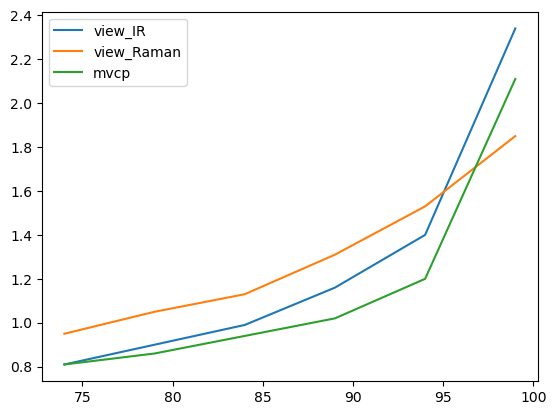

In [205]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-np.arange(.01,.3,.05))*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])

In [206]:
df_res_all 

cp,view_IR,view_Raman,mvcp,confidence
0,2.344,1.852,2.112,99.0
0,1.400,1.534,1.196,94.0
0,1.156,1.314,1.024,89.0
0,0.992,1.132,0.936,84.0
0,0.898,1.046,0.862,79.0
0,0.808,0.948,0.806,74.0


In [207]:
df_res_all = pd.concat(df_res_sd_lis, axis=0)
df_res_all['confidence'] = (1-np.arange(.01,.3,.05))*100
np.round(df_res_all, 2)

cp,view_IR,view_Raman,mvcp,confidence
0,0.45,0.10,0.50,99.0
0,0.10,0.12,0.09,94.0
0,0.06,0.11,0.06,89.0
0,0.05,0.05,0.04,84.0
0,0.03,0.04,0.05,79.0
0,0.04,0.06,0.06,74.0


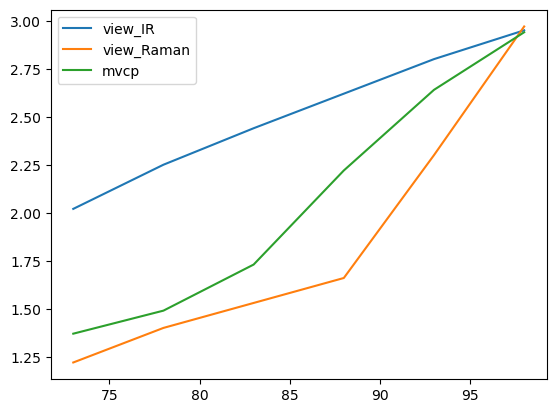

In [226]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-np.arange(.02,.3,.05))*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])

In [227]:
df_res_all 

cp,view_IR,view_Raman,mvcp,confidence
0,2.9472,2.9734,2.9424,98.0
0,2.8030,2.3050,2.6368,93.0
0,2.6206,1.6636,2.2244,88.0
0,2.4424,1.5280,1.7290,83.0
0,2.2496,1.3968,1.4878,78.0
0,2.0192,1.2244,1.3656,73.0


In [228]:
df_res_all = pd.concat(df_res_sd_lis, axis=0)
df_res_all['confidence'] = (1-np.arange(.02,.3,.05))*100
np.round(df_res_all, 2)

cp,view_IR,view_Raman,mvcp,confidence
0,0.05,0.04,0.06,98.0
0,0.11,0.30,0.15,93.0
0,0.17,0.12,0.32,88.0
0,0.20,0.12,0.22,83.0
0,0.23,0.13,0.15,78.0
0,0.27,0.13,0.15,73.0


In [229]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-np.arange(.02,.3,.05))*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,99.0,99.0,99.0,98.0
0,94.0,94.0,94.0,93.0
0,88.0,89.0,89.0,88.0
0,83.0,84.0,83.0,83.0
0,78.0,79.0,78.0,78.0
0,74.0,74.0,74.0,73.0


In [230]:
df_res_all = pd.concat(df_res_cov_sd_lis, axis=0)*100
df_res_all['confidence'] = (1-np.arange(.02,.3,.05))*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,1.0,1.0,1.0,98.0
0,4.0,4.0,3.0,93.0
0,6.0,5.0,5.0,88.0
0,6.0,6.0,6.0,83.0
0,7.0,7.0,7.0,78.0
0,8.0,7.0,7.0,73.0


In [96]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-np.arange(.01,.3,.05))*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,100.0,100.0,100.0,99.0
0,95.0,95.0,95.0,94.0
0,91.0,91.0,91.0,89.0
0,87.0,86.0,89.0,84.0
0,83.0,83.0,82.0,79.0
0,78.0,78.0,77.0,74.0


In [97]:
df_res_all = pd.concat(df_res_cov_sd_lis, axis=0)*100
df_res_all['confidence'] = (1-np.arange(.01,.3,.05))*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,0.0,1.0,1.0,99.0
0,4.0,5.0,5.0,94.0
0,6.0,7.0,7.0,89.0
0,7.0,8.0,8.0,84.0
0,8.0,11.0,10.0,79.0
0,8.0,10.0,10.0,74.0


In [66]:
df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res

cp,view_IR,view_Raman,mvcp
M,,,
2,0.835484,0.909677,0.793548


In [70]:
df_res = pd.DataFrame(pd.DataFrame(set_size).std()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res = df_res.reset_index(drop=True)
df_res

cp,view_IR,view_Raman,mvcp
0,0.082523,0.089706,0.066632


In [71]:
pd.concat([df_res, df_res], axis=0)

cp,view_IR,view_Raman,mvcp
0,0.082523,0.089706,0.066632
0,0.082523,0.089706,0.066632


In [69]:
df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
df_res

cp,view_IR,view_Raman,mvcp
M,,,
2,0.735484,0.76129,0.758065
